# Daily Internet Data Usage Forecasting Using Machine Learning
## Academic Mini-Project: Exploratory Data Analysis & Predictive Modeling

**Author:** Data Science Research Team  
**System Name:** NetUsage Analytics  
**Target Variable:** `total_data_usage_gb` (Regression)

---
### Table of Contents
1. [Environment Setup & Data Ingestion](#1.-Environment-Setup--Data-Ingestion)
2. [Exploratory Data Analysis (EDA)](#2.-Exploratory-Data-Analysis-(EDA))
3. [Feature Engineering & Leakage-Free Lag Generation](#3.-Feature-Engineering--Leakage-Free-Lag-Generation)
4. [Chronological Train-Test Split & Pipeline Preprocessing](#4.-Chronological-Train-Test-Split--Pipeline-Preprocessing)
5. [Machine Learning Model Training & Benchmarking](#5.-Machine-Learning-Model-Training--Benchmarking)
6. [Multi-Day Recursive Forecasting Simulation](#6.-Multi-Day-Recursive-Forecasting-Simulation)
7. [Unsupervised Anomaly Detection](#7.-Unsupervised-Anomaly-Detection)
8. [Academic Conclusions & Viva Summary](#8.-Academic-Conclusions--Viva-Summary)

In [1]:
# Ingestion and Library Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add root directory to sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.database import load_combined_data
from src.preprocessing import prepare_dataset_for_modeling
from src.train_models import get_models, evaluate_predictions
from src.anomaly_detection import run_comprehensive_anomaly_detection

# Visual configurations
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
print('Setup complete. All modules imported.')

Setup complete. All modules imported.


### 1. Ingesting the Longitudinal Internet Usage Diary Dataset
We load our historical consumption dataset spanning 2,200 daily records (2020 to 2026).

In [2]:
df = load_combined_data(base_csv_path='../data/internet_usage.csv', db_path='../data/usage_tracker.db')
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
display(df.head())

Dataset Shape: 2200 rows, 24 columns


date,day_of_week,is_weekend,month,season,is_holiday,video_streaming_hours,social_media_hours,online_gaming_hours,browsing_hours,video_calling_hours,downloading_gb,online_learning_hours,mobile_usage_gb,laptop_usage_gb,smart_tv_usage_gb,tablet_usage_gb,connected_devices_count,internet_plan_limit_gb,network_speed_mbps,wifi_connected_hours,number_of_users,total_data_usage_gb,is_manual
2020-01-01,Wednesday,0,1,Winter,1,3.82,0.68,0.10,2.77,0.64,2.00,1.54,2.01,3.23,6.15,1.49,7,750.0,300,17.46,2,14.11,0
2020-01-02,Thursday,0,1,Winter,1,5.70,1.45,0.07,2.08,1.02,0.33,1.20,3.24,2.00,9.55,1.91,7,750.0,150,16.40,3,18.34,0
2020-01-03,Friday,0,1,Winter,0,3.63,1.56,0.18,3.04,0.88,2.85,0.83,2.28,3.96,6.02,1.38,9,750.0,100,19.15,3,13.64,0
2020-01-04,Saturday,1,1,Winter,0,2.74,0.72,0.84,3.08,0.98,1.46,0.00,2.14,2.37,4.59,0.93,7,750.0,100,19.80,2,10.99,0
2020-01-05,Sunday,1,1,Winter,0,5.76,3.12,0.22,2.60,1.16,1.29,0.55,3.56,2.48,9.28,2.04,9,750.0,100,16.56,3,18.78,0


### 2. Exploratory Data Analysis (EDA)
Examining the statistical properties and distribution of `total_data_usage_gb`.

,is_weekend,month,is_holiday,video_streaming_hours,social_media_hours,online_gaming_hours,browsing_hours,video_calling_hours,downloading_gb,online_learning_hours,mobile_usage_gb,laptop_usage_gb,smart_tv_usage_gb,tablet_usage_gb,connected_devices_count,internet_plan_limit_gb,network_speed_mbps,wifi_connected_hours,number_of_users,total_data_usage_gb,is_manual
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2165.00,2200.00,2172.00,2200.00,2200.00,2200.00,2169.00,2200.00,2200.0,2200.00,2159.00,2200.00,2200.00,2200.0
mean,0.29,6.50,0.03,3.58,1.60,0.51,2.46,1.06,3.24,0.92,2.62,5.46,6.97,1.58,7.39,750.0,163.80,16.41,2.72,17.58,0.0
std,0.45,3.46,0.16,1.51,0.65,0.69,0.72,0.61,6.59,0.73,0.96,7.21,2.95,0.59,1.65,0.0,55.58,3.26,0.71,9.16,0.0
min,0.00,1.00,0.00,0.01,0.20,0.00,0.20,0.00,0.00,0.00,0.10,0.10,0.00,0.00,2.00,750.0,100.00,4.18,1.00,0.50,0.0
25%,0.00,3.75,0.00,2.51,1.15,0.10,2.01,0.61,0.69,0.22,1.93,2.55,4.91,1.19,6.00,750.0,150.00,14.36,2.00,12.67,0.0
50%,0.00,7.00,0.00,3.46,1.58,0.28,2.48,1.06,1.38,0.88,2.55,3.63,6.68,1.54,7.00,750.0,150.00,16.57,3.00,15.96,0.0
75%,1.00,10.00,0.00,4.46,2.03,0.65,2.95,1.49,2.00,1.52,3.21,5.21,8.70,1.93,9.00,750.0,200.00,18.65,3.00,19.62,0.0
max,1.00,12.00,1.00,9.46,3.83,7.00,4.54,2.92,44.96,3.53,6.79,58.49,20.78,4.28,13.00,750.0,300.00,24.00,5.00,75.36,0.0


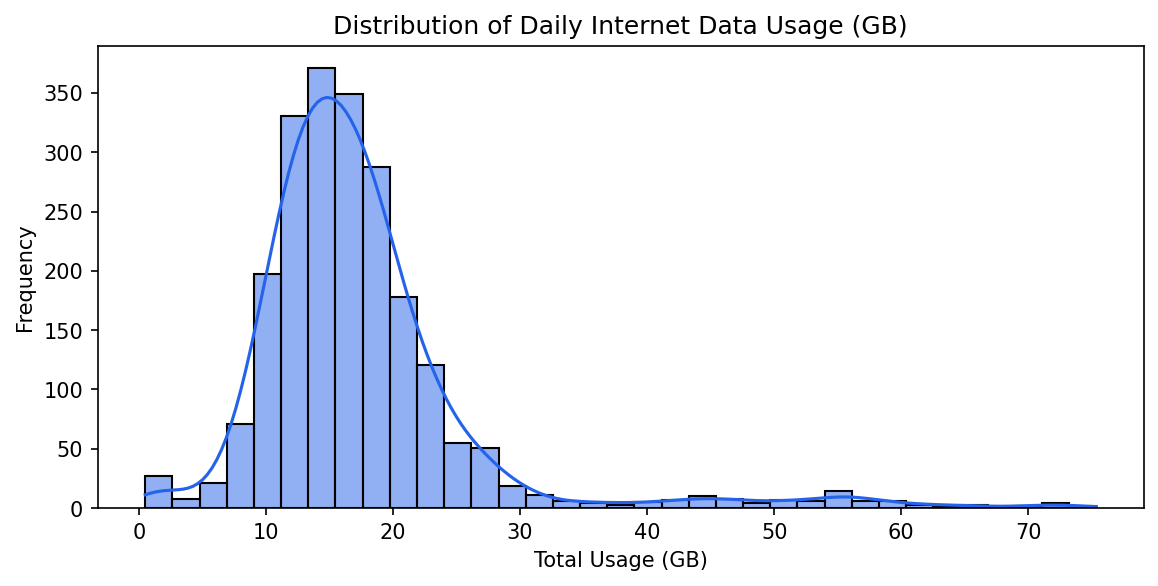

In [3]:
display(df.describe().round(2))

plt.figure(figsize=(9, 4))
sns.histplot(df['total_data_usage_gb'], kde=True, color='#2563eb', bins=35)
plt.title('Distribution of Daily Internet Data Usage (GB)')
plt.xlabel('Total Usage (GB)')
plt.ylabel('Frequency')
plt.show()

### 3. Chronological Train-Test Split and Preprocessing Pipeline
We apply an 80/20 chronological split to avoid time-series lookahead leakage.

In [4]:
X_train, X_test, y_train, y_test, preprocessor, feature_names, train_df, test_df = prepare_dataset_for_modeling(df, save_artifacts=False)
print(f'Train cohort: {X_train.shape[0]} days ({train_df["date"].min()} to {train_df["date"].max()})')
print(f'Test cohort:  {X_test.shape[0]} days ({test_df["date"].min()} to {test_df["date"].max()})')
print(f'Total engineered features: {len(feature_names)}')

Train cohort: 1760 days (2020-01-01 00:00:00 to 2024-10-25 00:00:00)
Test cohort:  440 days (2024-10-26 00:00:00 to 2026-01-08 00:00:00)
Total streamlined features: 12


### 4. Training and Evaluating Candidate Regression Models

In [5]:
models = get_models()
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    metrics = evaluate_predictions(y_test, preds)
    results.append({
        'Model': name,
        'Test MAE (GB)': metrics['MAE'],
        'Test RMSE (GB)': metrics['RMSE'],
        'Test R2': metrics['R2'],
        'Test MAPE (%)': metrics['MAPE']
    })

results_df = pd.DataFrame(results).sort_values('Test RMSE (GB)')
display(results_df)

Model,Test MAE (GB),Test RMSE (GB),Test R2,Test MAPE (%)
Linear Regression,0.4073,0.5218,0.9967,2.55
Gradient Boosting,0.6215,1.0438,0.9868,3.30
XGBoost,0.6707,1.0802,0.9859,3.45
Random Forest,0.7455,1.3725,0.9772,3.63
Decision Tree,1.0700,1.5405,0.9713,5.82


### 5. Anomaly Detection Demonstration
Testing Isolation Forest and IQR anomaly detection on consumption spikes.

In [6]:
df_anomalies, summary = run_comprehensive_anomaly_detection(df)
print('Anomaly Detection Summary:', summary)
display(df_anomalies[df_anomalies['is_anomaly']][['date', 'total_data_usage_gb', 'downloading_gb', 'anomaly_explanation']].head(10))

Anomaly Detection Summary: {'total_records_analyzed': 2200, 'total_anomalies_detected': 137, 'anomaly_rate_percent': 6.23, 'iqr_upper_threshold_gb': 30.04, 'max_anomalous_usage_gb': 75.36, 'academic_note': 'Identified anomalies represent statistical consumption variations and activity spikes. They do not imply cybersecurity breaches or unauthorized network intrusions.'}


date,total_data_usage_gb,downloading_gb,anomaly_explanation
2020-01-07,48.39,32.78,"Heavy download surge (32.8 GB downloaded vs 3.2 GB avg; e.g., large OS update, game install, or media archive)"
2020-01-14,40.83,28.07,"Heavy download surge (28.1 GB downloaded vs 3.2 GB avg; e.g., large OS update, game install, or media archive)"
2020-02-04,1.30,0.00,"Unusually low consumption (1.3 GB; potential travel, power outage, or absence from home)"
2020-02-08,36.05,20.46,"Heavy download surge (20.5 GB downloaded vs 3.2 GB avg; e.g., large OS update, game install, or media archive)"
2020-03-13,44.26,33.88,"Heavy download surge (33.9 GB downloaded vs 3.2 GB avg; e.g., large OS update, game install, or media archive)"
2020-04-14,36.86,25.46,"Heavy download surge (25.5 GB downloaded vs 3.2 GB avg; e.g., large OS update, game install, or media archive)"
2020-05-10,1.93,0.00,"Unusually low consumption (1.9 GB; potential travel, power outage, or absence from home)"
2020-05-31,44.74,33.32,"Heavy download surge (33.3 GB downloaded vs 3.2 GB avg; e.g., large OS update, game install, or media archive)"
